<a href="https://colab.research.google.com/github/saketraj-io/Deep-Learning-Lab_1BM24AI208/blob/main/Lab_Program_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Introduction to Hugging Face Hub & Model Cards

* **Hugging Face Hub:** An open-source platform and repository hosting pre-trained machine learning models, datasets, and demo apps (Spaces). It allows developers to download, fine-tune, and share models easily using Python libraries like `transformers` and `datasets`.
* **Model Cards:** Standardized documentation files (`README.md`) attached to models on the Hub. They provide transparency by detailing:
  * **Model Details:** Architecture, developer, version, and license.
  * **Intended Use:** Primary applications and out-of-scope use cases.
  * **Training Data & Procedure:** Datasets used for training and preprocessing steps.
  * **Evaluation & Limitations:** Benchmark metrics, known biases, and failure modes.

In [ ]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Dataset Structure:
 DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


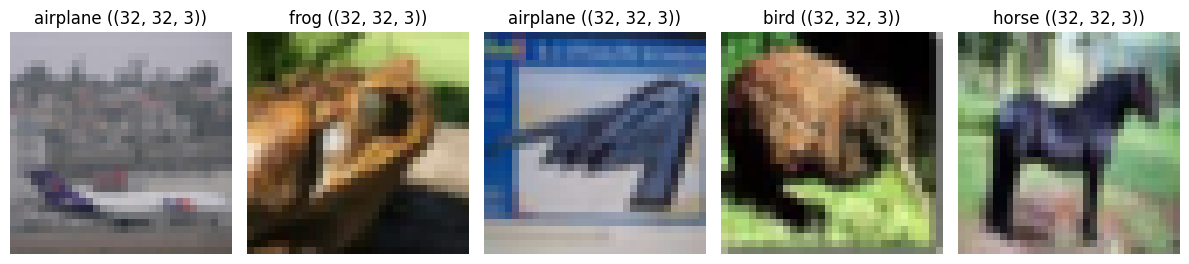

In [ ]:
# Load the CIFAR-10 dataset from Hugging Face Hub
dataset = load_dataset("uoft-cs/cifar10")

# Inspect dataset splits and features
print("Dataset Structure:\n", dataset)
class_names = dataset["train"].features["label"].names
print("\nClasses:", class_names)

# Extract and display the first 5 training images
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i in range(5):
    item = dataset["train"][i]
    image = np.array(item["img"])  # Convert PIL image to NumPy array (32x32x3)
    label = class_names[item["label"]]

    axes[i].imshow(image)
    axes[i].set_title(f"{label} ({image.shape})")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 2. 2D Convolution & Max-Pooling Using NumPy (From Scratch)

In [ ]:
def conv2d_numpy(image, kernel, stride=1, padding=0):
    """
    Applies a 2D convolution on a grayscale (2D) image using pure NumPy.
    """
    # Add zero padding around the image
    if padding > 0:
        image_padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant')
    else:
        image_padded = image

    img_h, img_w = image_padded.shape
    k_h, k_w = kernel.shape

    # Calculate output dimensions
    out_h = (img_h - k_h) // stride + 1
    out_w = (img_w - k_w) // stride + 1
    output = np.zeros((out_h, out_w))

    # Slide the kernel across the image
    for y in range(out_h):
        for x in range(out_w):
            region = image_padded[y * stride : y * stride + k_h, x * stride : x * stride + k_w]
            output[y, x] = np.sum(region * kernel)

    return output


def maxpool2d_numpy(feature_map, pool_size=2, stride=2):
    """
    Applies 2D max-pooling on a 2D feature map using pure NumPy.
    """
    fm_h, fm_w = feature_map.shape
    out_h = (fm_h - pool_size) // stride + 1
    out_w = (fm_w - pool_size) // stride + 1
    output = np.zeros((out_h, out_w))

    for y in range(out_h):
        for x in range(out_w):
            region = feature_map[y * stride : y * stride + pool_size, x * stride : x * stride + pool_size]
            output[y, x] = np.max(region)

    return output

Original Shape: (32, 32)
After Convolution (3x3, pad=1, stride=1): (32, 32)
After Max-Pooling (2x2, stride=2): (16, 16)


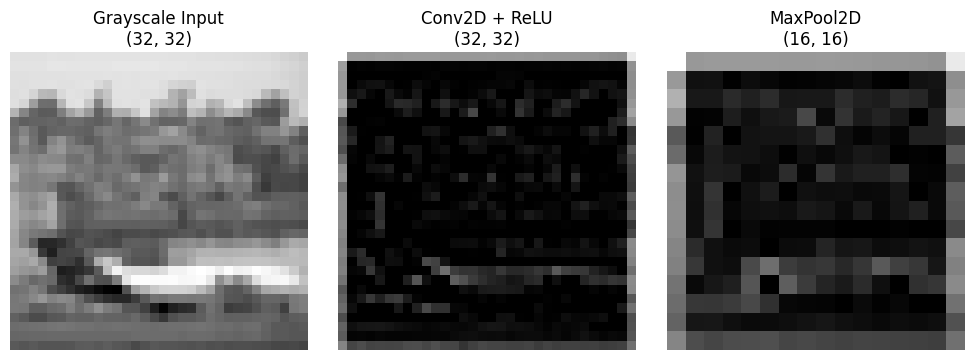

In [ ]:
# Take one image from CIFAR-10 and convert to grayscale (32x32) for clean 2D demonstration
sample_img = np.array(dataset["train"][0]["img"])
gray_img = np.mean(sample_img, axis=2)

# Define a 3x3 edge-detection kernel (Sobel-like filter)
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Apply NumPy Convolution and Max-Pooling
conv_out = conv2d_numpy(gray_img, edge_kernel, stride=1, padding=1)
relu_out = np.maximum(0, conv_out)  # ReLU activation
pool_out = maxpool2d_numpy(relu_out, pool_size=2, stride=2)

print(f"Original Shape: {gray_img.shape}")
print(f"After Convolution (3x3, pad=1, stride=1): {conv_out.shape}")
print(f"After Max-Pooling (2x2, stride=2): {pool_out.shape}")

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(gray_img, cmap="gray")
axes[0].set_title(f"Grayscale Input\n{gray_img.shape}")

axes[1].imshow(relu_out, cmap="gray")
axes[1].set_title(f"Conv2D + ReLU\n{relu_out.shape}")

axes[2].imshow(pool_out, cmap="gray")
axes[2].set_title(f"MaxPool2D\n{pool_out.shape}")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Exploring Kernel Size, Stride, and Padding

Input Image Shape: (32, 32)
---------------------------------------------
3x3 | Stride=1 | Pad=0 (Valid) -> Output Shape: (30, 30)
3x3 | Stride=1 | Pad=1 (Same)  -> Output Shape: (32, 32)
3x3 | Stride=2 | Pad=1         -> Output Shape: (16, 16)
5x5 | Stride=1 | Pad=0 (Valid) -> Output Shape: (28, 28)
5x5 | Stride=2 | Pad=2         -> Output Shape: (16, 16)


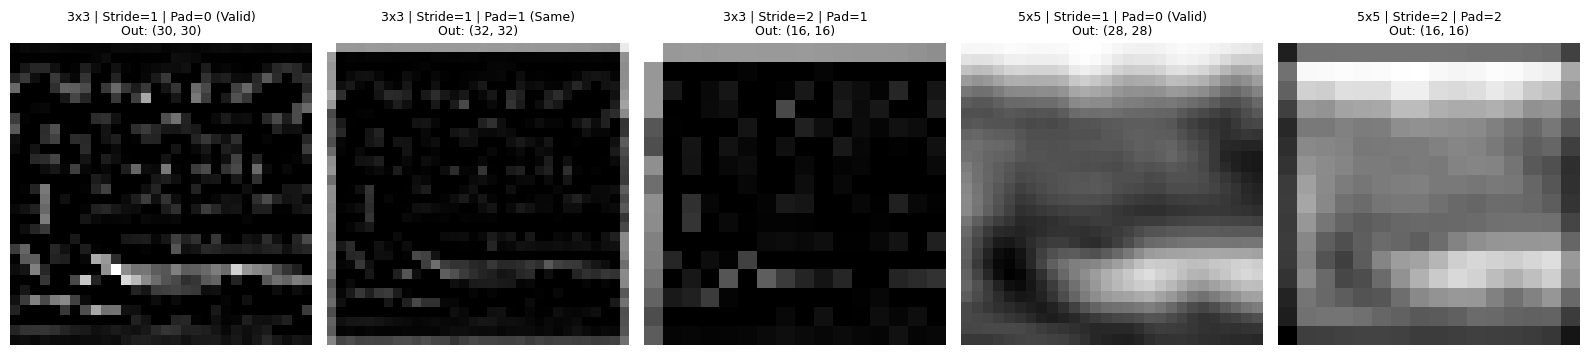

In [ ]:
# Define different kernels (3x3 and 5x5)
kernel_3x3 = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

kernel_5x5 = np.ones((5, 5)) / 25.0  # 5x5 averaging (blur) filter

# List of configurations: (Title, Kernel, Stride, Padding)
configs = [
    ("3x3 | Stride=1 | Pad=0 (Valid)", kernel_3x3, 1, 0),
    ("3x3 | Stride=1 | Pad=1 (Same)",  kernel_3x3, 1, 1),
    ("3x3 | Stride=2 | Pad=1",         kernel_3x3, 2, 1),
    ("5x5 | Stride=1 | Pad=0 (Valid)", kernel_5x5, 1, 0),
    ("5x5 | Stride=2 | Pad=2",         kernel_5x5, 2, 2),
]

fig, axes = plt.subplots(1, len(configs), figsize=(16, 3.5))

print(f"Input Image Shape: {gray_img.shape}\n" + "-"*45)

for idx, (title, k, s, p) in enumerate(configs):
    out = conv2d_numpy(gray_img, k, stride=s, padding=p)
    out_relu = np.maximum(0, out)

    print(f"{title:<30} -> Output Shape: {out_relu.shape}")

    axes[idx].imshow(out_relu, cmap="gray")
    axes[idx].set_title(f"{title}\nOut: {out_relu.shape}", fontsize=9)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

## 4. Basic CNN for CIFAR-10 Classification

In [ ]:
# Uncomment below if torch/torchvision are not installed
# !pip install torch torchvision

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms

# Check for GPU, fallback to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Transform PIL images to normalized PyTorch tensors
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

def apply_transforms(batch):
    batch["pixel_values"] = [transform(img.convert("RGB")) for img in batch["img"]]
    return batch

# Apply transforms to the Hugging Face dataset loaded in Section 1
train_ds = dataset["train"].with_transform(apply_transforms)
test_ds = dataset["test"].with_transform(apply_transforms)

def collate_fn(batch):
    images = torch.stack([item["pixel_values"] for item in batch])
    labels = torch.tensor([item["label"] for item in batch])
    return images, labels

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, collate_fn=collate_fn)

# Define a Basic 3-Layer CNN
class BasicCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # 32x32x32
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                           # 16x16x32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 16x16x64
            nn.ReLU(),
            nn.MaxPool2d(2, 2),                           # 8x8x64

            nn.Conv2d(64, 64, kernel_size=3, padding=1),  # 8x8x64
            nn.ReLU(),
            nn.MaxPool2d(2, 2)                            # 4x4x64
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = BasicCNN().to(device)
print(model)

Using device: cpu
BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5  # Increase to 10 if running on GPU for higher accuracy

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {running_loss/len(train_loader):.4f}")

# Evaluate on the CIFAR-10 Test Set
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"\nTest Accuracy on 10,000 CIFAR-10 images: {100 * correct / total:.2f}%")

Epoch [1/5] - Loss: 1.4678
Epoch [2/5] - Loss: 1.0694
Epoch [3/5] - Loss: 0.8867
Epoch [4/5] - Loss: 0.7730
Epoch [5/5] - Loss: 0.6875

Test Accuracy on 10,000 CIFAR-10 images: 71.83%
